In [2]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [4]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [5]:
df = pd.read_csv("Cleaned_Sales_Dataset.csv")

In [6]:
Path("Charts").mkdir(exist_ok=True)
Path("SQL_Results").mkdir(exist_ok=True)

In [7]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Duplicate_Order_ID_Flag,Order_Year,Order_Month,Age_Group
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,False,2025,February,26-35
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80,False,2025,October,56-65
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48,False,2025,May,56-65
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,False,2025,December,56-65
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,False,2025,November,36-45


In [8]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Duplicate_Order_ID_Flag,Order_Year,Order_Month,Age_Group
995,ORD100997,2025-11-07,CUST6410,Customer_301,61.0,Male,Gaya,Laptop,Electronics,9,35405.54,318649.86,False,2025,November,56-65
996,ORD100998,2025-09-03,CUST7618,Customer_154,25.0,Male,Gaya,Shoes,Fashion,5,18454.65,92273.25,False,2025,September,18-25
997,ORD100999,2025-09-30,CUST9544,Customer_140,62.0,Female,Hyderabad,Laptop,Electronics,9,12971.59,116744.31,False,2025,September,56-65
998,ORD101000,2025-02-21,CUST9501,Customer_241,41.0,Male,Delhi,Mobile,Electronics,9,2879.01,25911.09,False,2025,February,36-45
999,ORD101001,2025-04-23,CUST2714,Customer_98,58.0,Female,Gaya,Chair,Furniture,9,22493.87,202444.83,False,2025,April,56-65


In [9]:
df.shape

(1000, 16)

In [10]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales', 'Duplicate_Order_ID_Flag', 'Order_Year', 'Order_Month',
       'Age_Group'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Order_ID                 1000 non-null   object 
 1   Order_Date               1000 non-null   object 
 2   Customer_ID              1000 non-null   object 
 3   Customer_Name            1000 non-null   object 
 4   Age                      1000 non-null   float64
 5   Gender                   1000 non-null   object 
 6   City                     1000 non-null   object 
 7   Product                  1000 non-null   object 
 8   Category                 1000 non-null   object 
 9   Quantity                 1000 non-null   int64  
 10  Unit_Price               1000 non-null   float64
 11  Total_Sales              1000 non-null   float64
 12  Duplicate_Order_ID_Flag  1000 non-null   bool   
 13  Order_Year               1000 non-null   int64  
 14  Order_Month              

In [12]:
df.describe()

,Age,Quantity,Unit_Price,Total_Sales,Order_Year
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,41.353000,5.435000,25486.783410,139399.439650,2025.005000
std,13.683626,2.838632,14179.402361,114100.051546,0.070569
min,18.000000,1.000000,145.780000,437.340000,2025.000000
25%,30.000000,3.000000,13895.722500,47066.632500,2025.000000
50%,41.000000,5.000000,25398.740000,108594.025000,2025.000000
75%,53.000000,8.000000,37512.382500,203722.882500,2025.000000
max,65.000000,10.000000,49997.530000,493677.500000,2026.000000


In [13]:
df.describe(include="object")

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,City,Product,Category,Order_Month,Age_Group
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,992,342,947,425,2,9,6,5,12,5
top,ORD100050,2025-04-16,CUST2515,Customer_359,Male,Patna,Mobile,Electronics,December,36-45
freq,9,10,3,8,511,135,184,354,98,223


In [14]:
#finds the total null values
df.isnull().sum()

Order_ID                   0
Order_Date                 0
Customer_ID                0
Customer_Name              0
Age                        0
Gender                     0
City                       0
Product                    0
Category                   0
Quantity                   0
Unit_Price                 0
Total_Sales                0
Duplicate_Order_ID_Flag    0
Order_Year                 0
Order_Month                0
Age_Group                  0
dtype: int64

In [15]:
#finds the total duplicates
df.duplicated().sum()

np.int64(0)

In [16]:
#find the duplicates in order_id
df["Order_ID"].duplicated().sum()

np.int64(8)

In [17]:
#converts date in to a format
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [18]:
df["Order_Date"].dtype

dtype('<M8[ns]')

In [19]:
#calculates mean
df[["Age", "Quantity", "Unit_Price", "Total_Sales"]].mean()

Age                41.35300
Quantity            5.43500
Unit_Price      25486.78341
Total_Sales    139399.43965
dtype: float64

In [20]:
#calculates median
df[["Age", "Quantity", "Unit_Price", "Total_Sales"]].median()

Age                41.000
Quantity            5.000
Unit_Price      25398.740
Total_Sales    108594.025
dtype: float64

In [21]:
#calculates mode
df[["Age", "Quantity", "Unit_Price", "Total_Sales"]].mode()

,Age,Quantity,Unit_Price,Total_Sales
0,41.0,4.0,145.78,437.34
1,NaN,5.0,257.28,767.61
2,NaN,6.0,283.10,771.84
3,NaN,NaN,315.67,1005.21
4,NaN,NaN,349.06,1144.78
...,...,...,...,...
995,NaN,NaN,49685.64,482551.90
996,NaN,NaN,49735.32,485667.80
997,NaN,NaN,49876.67,490866.40
998,NaN,NaN,49889.13,492174.10


In [22]:
#Calculates standard deviation
df[["Age", "Quantity", "Unit_Price", "Total_Sales"]].std()

Age                13.683626
Quantity            2.838632
Unit_Price      14179.402361
Total_Sales    114100.051546
dtype: float64

In [23]:
#Find minimum and maximum
df[["Age", "Quantity", "Unit_Price", "Total_Sales"]].agg(
    ["min", "max"]
)

,Age,Quantity,Unit_Price,Total_Sales
min,18.0,1,145.78,437.34
max,65.0,10,49997.53,493677.50


In [24]:
#Create one complete statistical summary
statistics = df[    ["Age", "Quantity", "Unit_Price", "Total_Sales"]].describe()
statistics

,Age,Quantity,Unit_Price,Total_Sales
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,41.353000,5.435000,25486.783410,139399.439650
std,13.683626,2.838632,14179.402361,114100.051546
min,18.000000,1.000000,145.780000,437.340000
25%,30.000000,3.000000,13895.722500,47066.632500
50%,41.000000,5.000000,25398.740000,108594.025000
75%,53.000000,8.000000,37512.382500,203722.882500
max,65.000000,10.000000,49997.530000,493677.500000


In [25]:
#saves this summary
statistics.to_csv("Descriptive_Statistics.csv")

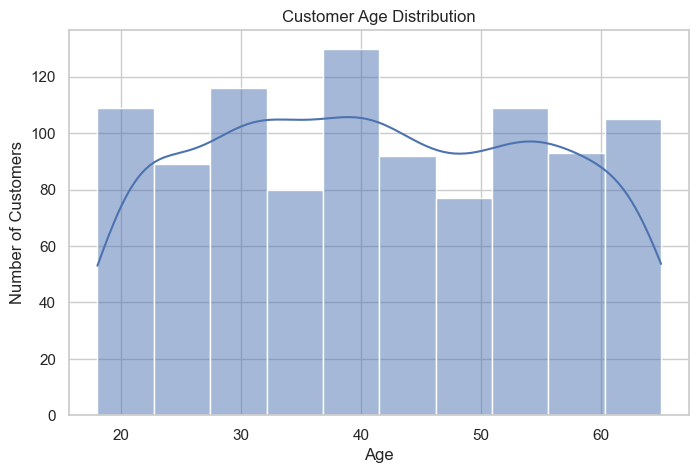

In [26]:
#customer age distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Age"].dropna(), bins=10, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.savefig("Charts/Age_Distribution.png", bbox_inches="tight")
plt.show()

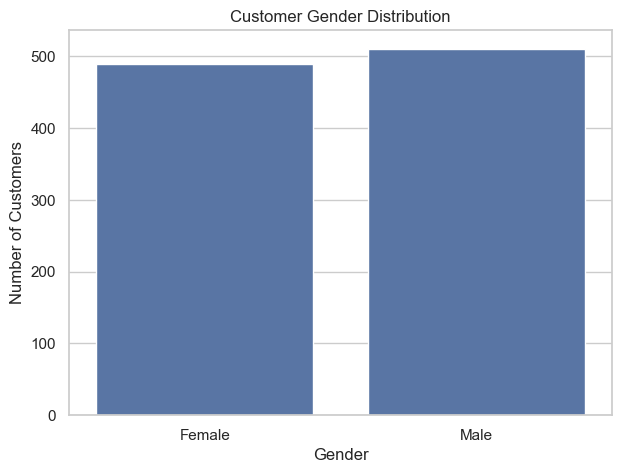

In [27]:
#gender distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.savefig("Charts/Gender_Distribution.png", bbox_inches="tight")
plt.show()

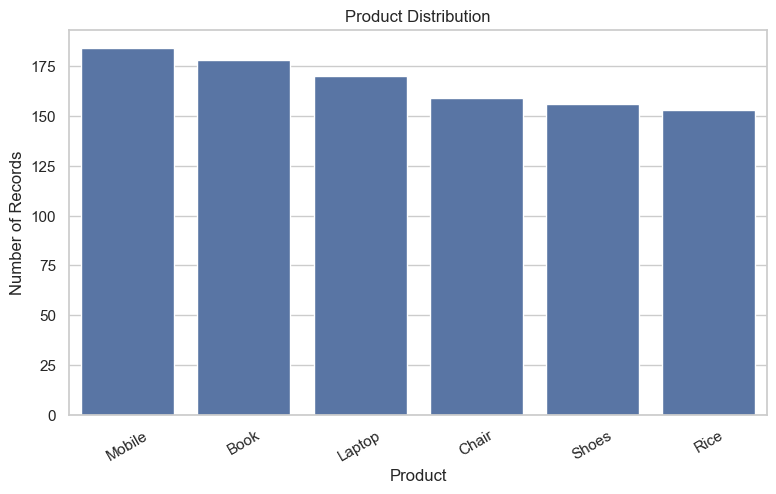

In [28]:
#product distibution
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Product",
    order=df["Product"].value_counts().index
)

plt.title("Product Distribution")
plt.xlabel("Product")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

plt.savefig("Charts/Product_Distribution.png", bbox_inches="tight")
plt.show()

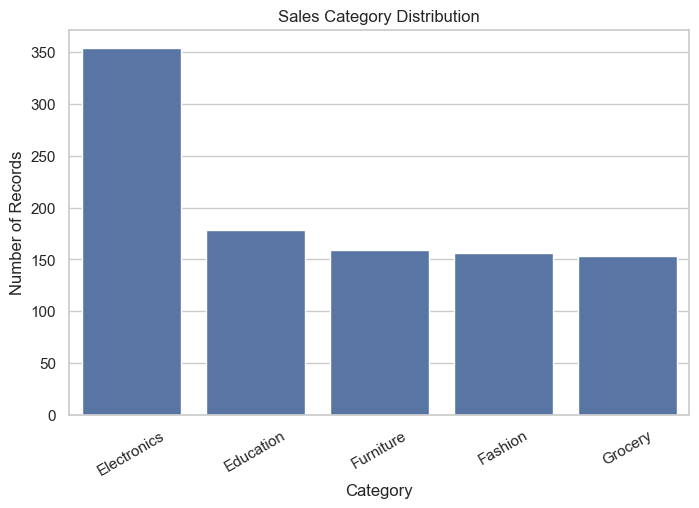

In [29]:
#category distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Category",
    order=df["Category"].value_counts().index
)

plt.title("Sales Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

plt.savefig("Charts/Category_Distribution.png", bbox_inches="tight")
plt.show()

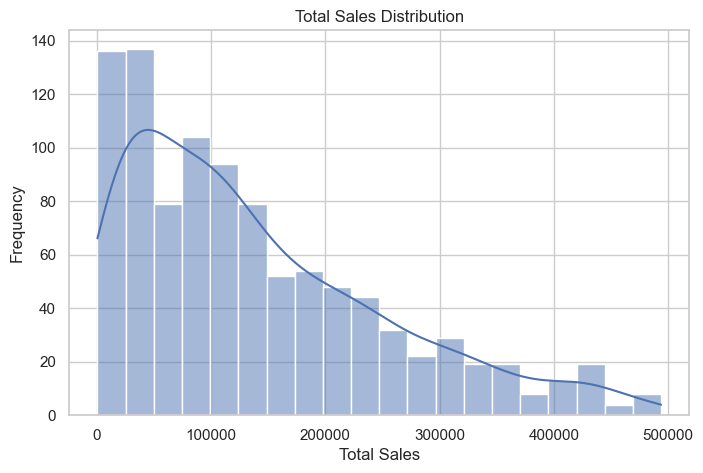

In [30]:
#Total sales distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Total_Sales"], bins=20, kde=True)

plt.title("Total Sales Distribution")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")

plt.savefig("Charts/Total_Sales_Distribution.png", bbox_inches="tight")
plt.show()

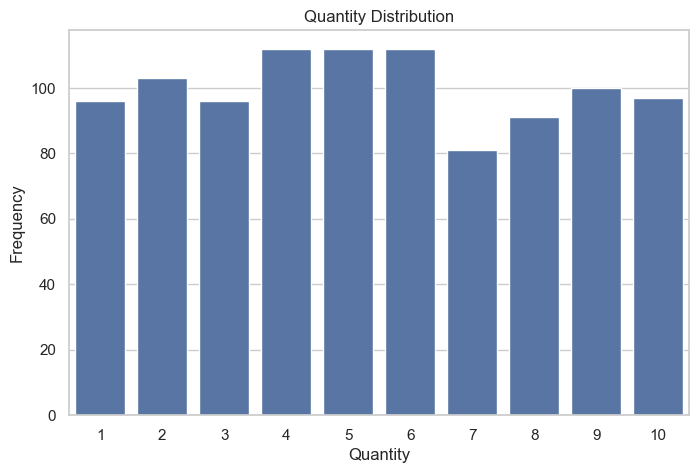

In [31]:
#quantity distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Quantity")

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.savefig("Charts/Quantity_Distribution.png", bbox_inches="tight")
plt.show()

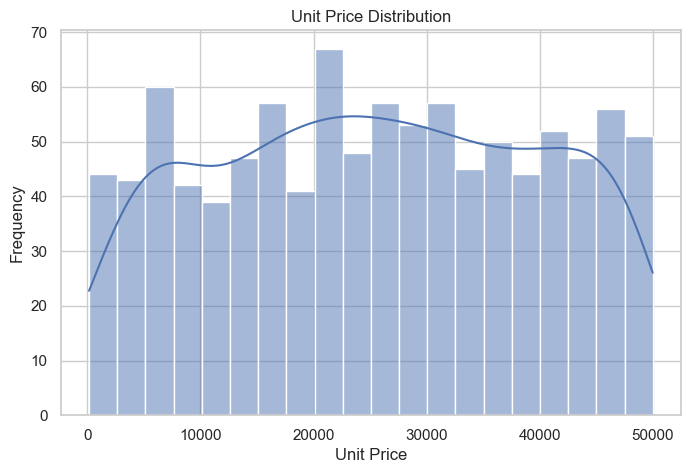

In [32]:
#unit price distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Unit_Price"], bins=20, kde=True)

plt.title("Unit Price Distribution")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")

plt.savefig("Charts/Unit_Price_Distribution.png", bbox_inches="tight")
plt.show()

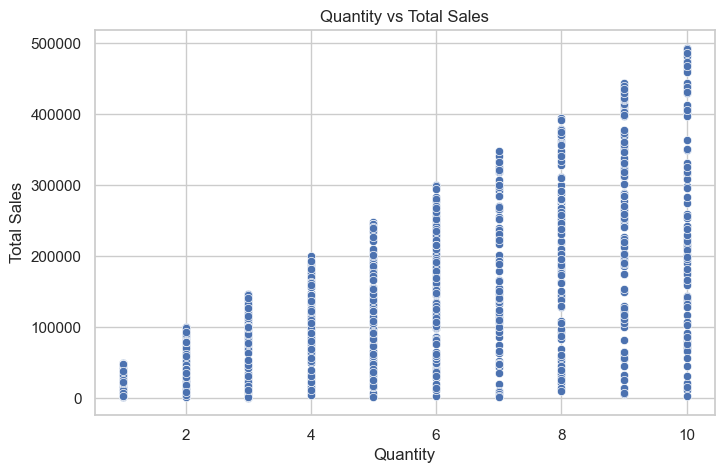

In [33]:
#multivariate analysis
#Quantity vs Total Sales
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total_Sales"
)

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.savefig("Charts/Quantity_vs_Total_Sales.png", bbox_inches="tight")
plt.show()

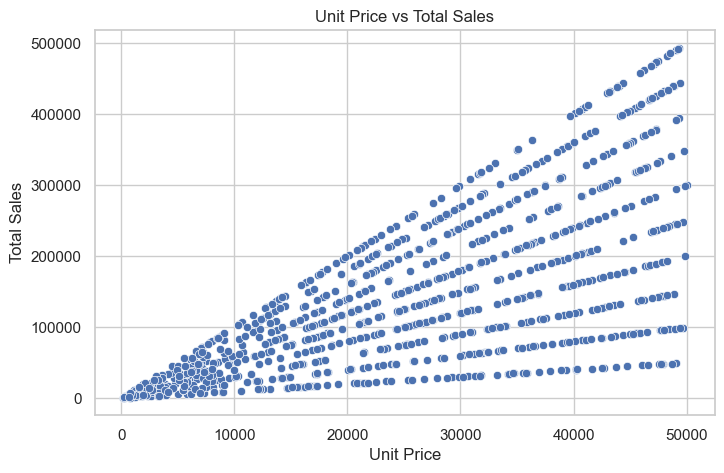

In [34]:
#Unit Price vs Total Sales
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Unit_Price",
    y="Total_Sales"
)

plt.title("Unit Price vs Total Sales")
plt.xlabel("Unit Price")
plt.ylabel("Total Sales")

plt.savefig("Charts/Unit_Price_vs_Total_Sales.png", bbox_inches="tight")
plt.show()

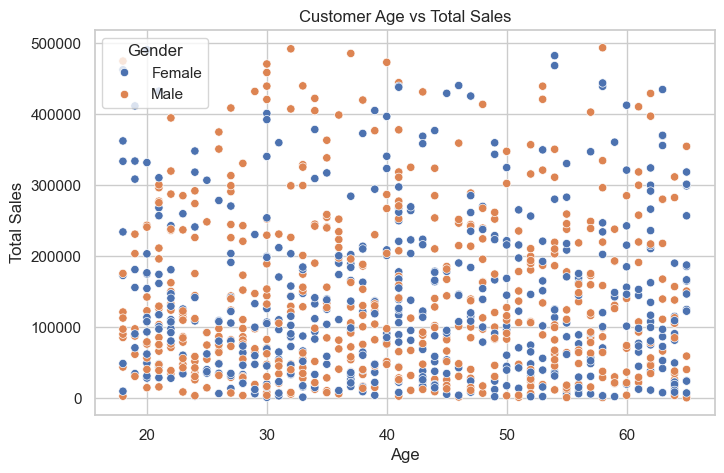

In [35]:
#Age vs Total Sales
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Total_Sales",
    hue="Gender"
)

plt.title("Customer Age vs Total Sales")
plt.xlabel("Age")
plt.ylabel("Total Sales")

plt.savefig("Charts/Age_vs_Total_Sales.png", bbox_inches="tight")
plt.show()

In [37]:
#Correlation Heatmap
numeric_df = df[
    ["Age", "Quantity", "Unit_Price", "Total_Sales"]
]
correlation = numeric_df.corr()

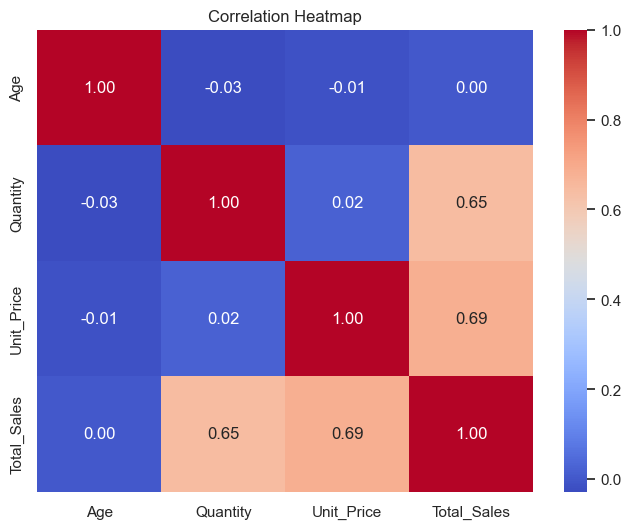

In [38]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.savefig("Charts/Correlation_Heatmap.png", bbox_inches="tight")
plt.show()

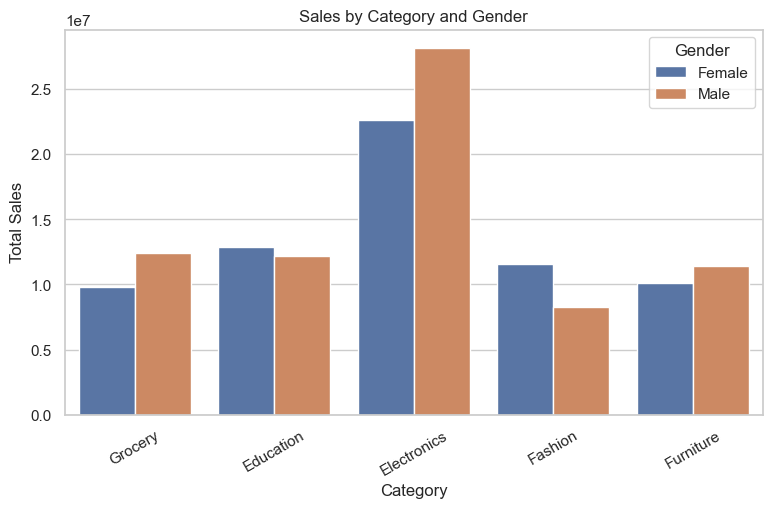

In [39]:
#Category-wise Sales by Gender
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Category",
    y="Total_Sales",
    hue="Gender",
    estimator="sum",
    errorbar=None
)

plt.title("Sales by Category and Gender")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)

plt.savefig("Charts/Category_Gender_Sales.png", bbox_inches="tight")
plt.show()
